In [3]:
import pandas as pd
import requests
from pathlib import Path

data_path = Path("../data/clean/studies_raw.parquet")

In [7]:
df = pd.read_parquet(data_path)
df

,Space Program,Flight Program,Study Assay Measurement Type,Study Protocol Description,Material Type,Study Identifier,ESA Acronym,Acknowledgments,Managing NASA Center,Data Source Type,...,Parameter Value,Identifiers,Data Source Accession,_id,Study Person.First Name,Study Person.Middle Initials,Study Person.Last Name,Mission.Start Date,Mission.End Date,Mission.Name
0,,,genome sequencing,Bacillus horneckiae strain 1P01SC was isolated...,cells,OSD-263,,,Ames Research Center (ARC),cgene,...,,GLDS-263,PISD00000000 PISE00000000 PISK01000000 PISJ...,iN_6g4QB28eYt3lGObYG,Kasthuri Arman Parag Kerry,,Venkateswaran Seuylemezian Vaishampayan Cooper,,,
1,NASA,Internation Space Station (ISS),genome sequencing,Samples were obtained from 5 locations across ...,Cells,OSD-311,,,Jet Propulsion Laboratory (JPL),cgene,...,,GLDS-311,PRJNA635942,T9_6g4QB28eYt3lGNLaB,Kasthuri Achintya,,Venkateswaran Bharadwaj,,,
2,NASA,Internation Space Station (ISS),genome sequencing,Samples were obtained from 5 locations across ...,Cells,OSD-302,,,Jet Propulsion Laboratory (JPL),cgene,...,,GLDS-302,PRJNA635942,kN_6g4QB28eYt3lGObaP,Kasthuri Achintya,,Venkateswaran Bharadwaj,,,
3,NASA,Internation Space Station (ISS),genome sequencing,During the course of the Veggie project (a veg...,Cells,OSD-177,,,Ames Research Center (ARC),cgene,...,,GLDS-177,PRJNA437451,D9_6g4QB28eYt3lGL7b9,Kasthuri Camilla,,Venkateswaran Urbaniak,18-Apr-2014,18-May-2014,SpaceX-3
4,NASA,Internation Space Station (ISS),genome sequencing,Purified culture were subjected to DNA extract...,Cells,OSD-293,,,Jet Propulsion Laboratory (JPL),cgene,...,,GLDS-293,PRJNA625575 PRJNA628952,4d_6g4QB28eYt3lGLLV-,Kasthuri Robert,,Venkateswaran Daudu,,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
572,NASA; NIH,International Space Station (ISS),transcription profiling,Vastus lateralis biopsies were obtained from v...,Myoblasts,OSD-684,,We acknowledge undergraduate scholarship suppo...,Kennedy Space Center (KSC),cgene,...,,GLDS-615,GSE234465,j54XG44BKCnU7lGjpbmW,Maddalena Shelby Tushar S Jorge A Meghan Legra...,,Parafati Giza Shenoy Mojica-Santiago Hopf Mala...,12/05/2020,01/13/2021,SpaceX-21
573,,,protein expression profiling protein expre...,cfDNA was extracted using Qiagen’s QIAamp ccfD...,Plasma,OSD-571,,"Thanks to the WorldQuant Foundation, NASA , th...",,cgene,...,,GLDS-563,,cHTneY8BcirjsmJn-V2B,Christopher Eliah Nadia Irina Karolina Laura A...,E G.,Mason Overbey Houerbi Matei Sienkiewicz Patras...,09/16/2021,09/18/2021,SpaceX Inspiration4
574,NASA,International Space Station (ISS),transcription profiling Chromatin Accessib...,In the Rodent Research Reference Mission (RRRM...,Left cerebral hemisphere,OSD-613,,,Ames Research Center (ARC),cgene,...,,GLDS-589,,fhvSsYkBiXs0LFsRBcgi,Lauren Cassie Egle Louis Michael Sylvain Samra...,,Sanders Juran Cekanaviciute Stodieck Roberts C...,07/25/2019,08/27/2019,SpaceX-18
575,NASA,,transcription profiling protein expression...,A cohort of 16-week-old female C57BL/6J mice (...,Liver,OSD-48,,,Ames Research Center (ARC),alsda cgene,...,,GLDS-48 LSDS-2,,lN_6g4QB28eYt3lGObbt,Ruth Oana Amanda Nicholas Samrawit Jonathan Ka...,V,Globus Marcu Saravia-Butler Bense Gebre Galazk...,9/21/14,10/25/2014,SpaceX-4


# Some general stats about the dataset

In [ ]:
# Some general stats about the dataset
print(f"Number of studies: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")
print(f"Column names: {list(df.columns)}")

# number of missing values per column
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values[missing_values > 0])
print()

# number of empty strings per column
empty_strings = (df == "").sum()
print("Empty strings per column:")
print(empty_strings[empty_strings > 0])
print()

# number of strings that are just "NA" or "N/A" or whitespace per column
na_strings = df.map(lambda x: isinstance(x, str) and x.strip().upper() in ["NA", "N/A"]).sum()
print("NA strings per column:")
print(na_strings[na_strings > 0])
print()

Number of studies: 577
Number of columns: 44
Column names: ['Space Program', 'Flight Program', 'Study Assay Measurement Type', 'Study Protocol Description', 'Material Type', 'Study Identifier', 'ESA Acronym', 'Acknowledgments', 'Managing NASA Center', 'Data Source Type', 'Study Grant Number', 'Experiment Platform', 'Study Factor Name', 'Study Publication Author List', 'Study Assay Technology Platform', 'Authoritative Source URL', 'Project Identifier', 'thumbnail', 'Project Title', 'Study Public Release Date', 'Project Link', 'Study Publication Title', 'organism', 'Accession', 'Study Assay Technology Type', 'Study Title', 'Study Protocol Type', 'Project Type', 'Study Funding Agency', 'Study Factor Type', 'Factor Value', 'Study Description', 'Study Protocol Name', 'Characteristics', 'Parameter Value', 'Identifiers', 'Data Source Accession', '_id', 'Study Person.First Name', 'Study Person.Middle Initials', 'Study Person.Last Name', 'Mission.Start Date', 'Mission.End Date', 'Mission.Name']

In [16]:
# replace empty strings, NA strings, and whitespace-only strings with NaN
df.replace(r'^\s*$', pd.NA, regex=True, inplace=True)
df.replace(r'(?i)^(NA|N/A)$', pd.NA, regex=True, inplace=True)

df

,Space Program,Flight Program,Study Assay Measurement Type,Study Protocol Description,Material Type,Study Identifier,ESA Acronym,Acknowledgments,Managing NASA Center,Data Source Type,...,Parameter Value,Identifiers,Data Source Accession,_id,Study Person.First Name,Study Person.Middle Initials,Study Person.Last Name,Mission.Start Date,Mission.End Date,Mission.Name
0,NaN,NaN,genome sequencing,Bacillus horneckiae strain 1P01SC was isolated...,cells,OSD-263,NaN,NaN,Ames Research Center (ARC),cgene,...,NaN,GLDS-263,PISD00000000 PISE00000000 PISK01000000 PISJ...,iN_6g4QB28eYt3lGObYG,Kasthuri Arman Parag Kerry,NaN,Venkateswaran Seuylemezian Vaishampayan Cooper,NaN,NaN,NaN
1,NASA,Internation Space Station (ISS),genome sequencing,Samples were obtained from 5 locations across ...,Cells,OSD-311,NaN,NaN,Jet Propulsion Laboratory (JPL),cgene,...,NaN,GLDS-311,PRJNA635942,T9_6g4QB28eYt3lGNLaB,Kasthuri Achintya,NaN,Venkateswaran Bharadwaj,NaN,NaN,NaN
2,NASA,Internation Space Station (ISS),genome sequencing,Samples were obtained from 5 locations across ...,Cells,OSD-302,NaN,NaN,Jet Propulsion Laboratory (JPL),cgene,...,NaN,GLDS-302,PRJNA635942,kN_6g4QB28eYt3lGObaP,Kasthuri Achintya,NaN,Venkateswaran Bharadwaj,NaN,NaN,NaN
3,NASA,Internation Space Station (ISS),genome sequencing,During the course of the Veggie project (a veg...,Cells,OSD-177,NaN,NaN,Ames Research Center (ARC),cgene,...,NaN,GLDS-177,PRJNA437451,D9_6g4QB28eYt3lGL7b9,Kasthuri Camilla,NaN,Venkateswaran Urbaniak,18-Apr-2014,18-May-2014,SpaceX-3
4,NASA,Internation Space Station (ISS),genome sequencing,Purified culture were subjected to DNA extract...,Cells,OSD-293,NaN,NaN,Jet Propulsion Laboratory (JPL),cgene,...,NaN,GLDS-293,PRJNA625575 PRJNA628952,4d_6g4QB28eYt3lGLLV-,Kasthuri Robert,NaN,Venkateswaran Daudu,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
572,NASA; NIH,International Space Station (ISS),transcription profiling,Vastus lateralis biopsies were obtained from v...,Myoblasts,OSD-684,NaN,We acknowledge undergraduate scholarship suppo...,Kennedy Space Center (KSC),cgene,...,NaN,GLDS-615,GSE234465,j54XG44BKCnU7lGjpbmW,Maddalena Shelby Tushar S Jorge A Meghan Legra...,NaN,Parafati Giza Shenoy Mojica-Santiago Hopf Mala...,12/05/2020,01/13/2021,SpaceX-21
573,NaN,NaN,protein expression profiling protein expre...,cfDNA was extracted using Qiagen’s QIAamp ccfD...,Plasma,OSD-571,NaN,"Thanks to the WorldQuant Foundation, NASA , th...",NaN,cgene,...,NaN,GLDS-563,NaN,cHTneY8BcirjsmJn-V2B,Christopher Eliah Nadia Irina Karolina Laura A...,E G.,Mason Overbey Houerbi Matei Sienkiewicz Patras...,09/16/2021,09/18/2021,SpaceX Inspiration4
574,NASA,International Space Station (ISS),transcription profiling Chromatin Accessib...,In the Rodent Research Reference Mission (RRRM...,Left cerebral hemisphere,OSD-613,NaN,NaN,Ames Research Center (ARC),cgene,...,NaN,GLDS-589,NaN,fhvSsYkBiXs0LFsRBcgi,Lauren Cassie Egle Louis Michael Sylvain Samra...,NaN,Sanders Juran Cekanaviciute Stodieck Roberts C...,07/25/2019,08/27/2019,SpaceX-18
575,NASA,NaN,transcription profiling protein expression...,A cohort of 16-week-old female C57BL/6J mice (...,Liver,OSD-48,NaN,NaN,Ames Research Center (ARC),alsda cgene,...,NaN,GLDS-48 LSDS-2,NaN,lN_6g4QB28eYt3lGObbt,Ruth Oana Amanda Nicholas Samrawit Jonathan Ka...,V,Globus Marcu Saravia-Butler Bense Gebre Galazk...,9/21/14,10/25/2014,SpaceX-4


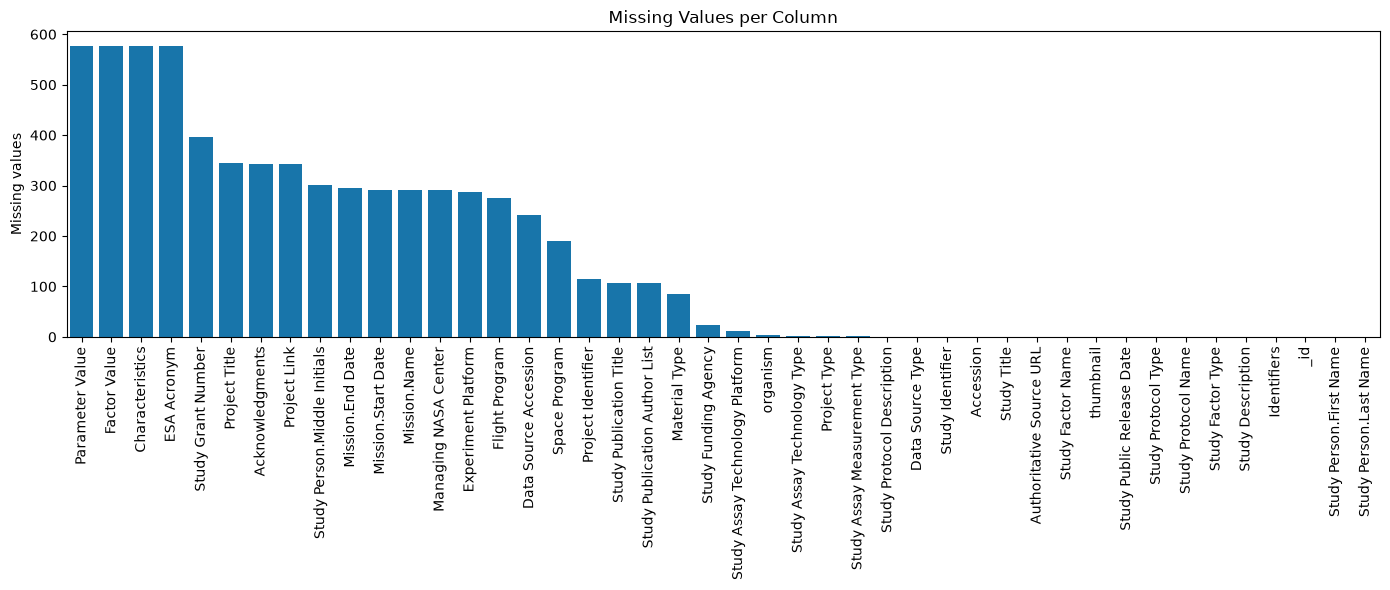

In [ ]:
# plot completeness of each column, percentage barchart
import matplotlib.pyplot as plt
import seaborn as sns

missing = df.isnull().sum().sort_values(ascending=False)

plt.figure(figsize=(14, 6))
sns.barplot(x=missing.index, y=missing.values, color="#007bc2")
plt.title("Missing Values per Column")
plt.xlabel("")
plt.ylabel("Missing values")
plt.xticks(rotation=90)  # or rotation=45, ha="right" for angled labels
plt.tight_layout()
plt.show()

,missing_pct,n_unique,median_len
column,,,
Study Protocol Description,0.0,563,5671.0
Study Identifier,0.0,576,7.0
Study Factor Name,0.0,260,29.0
Data Source Type,0.0,3,5.0
Authoritative Source URL,0.0,576,8.0
Accession,0.0,576,7.0
Study Public Release Date,0.0,409,12.0
thumbnail,0.0,576,34.0
Study Title,0.0,575,104.0


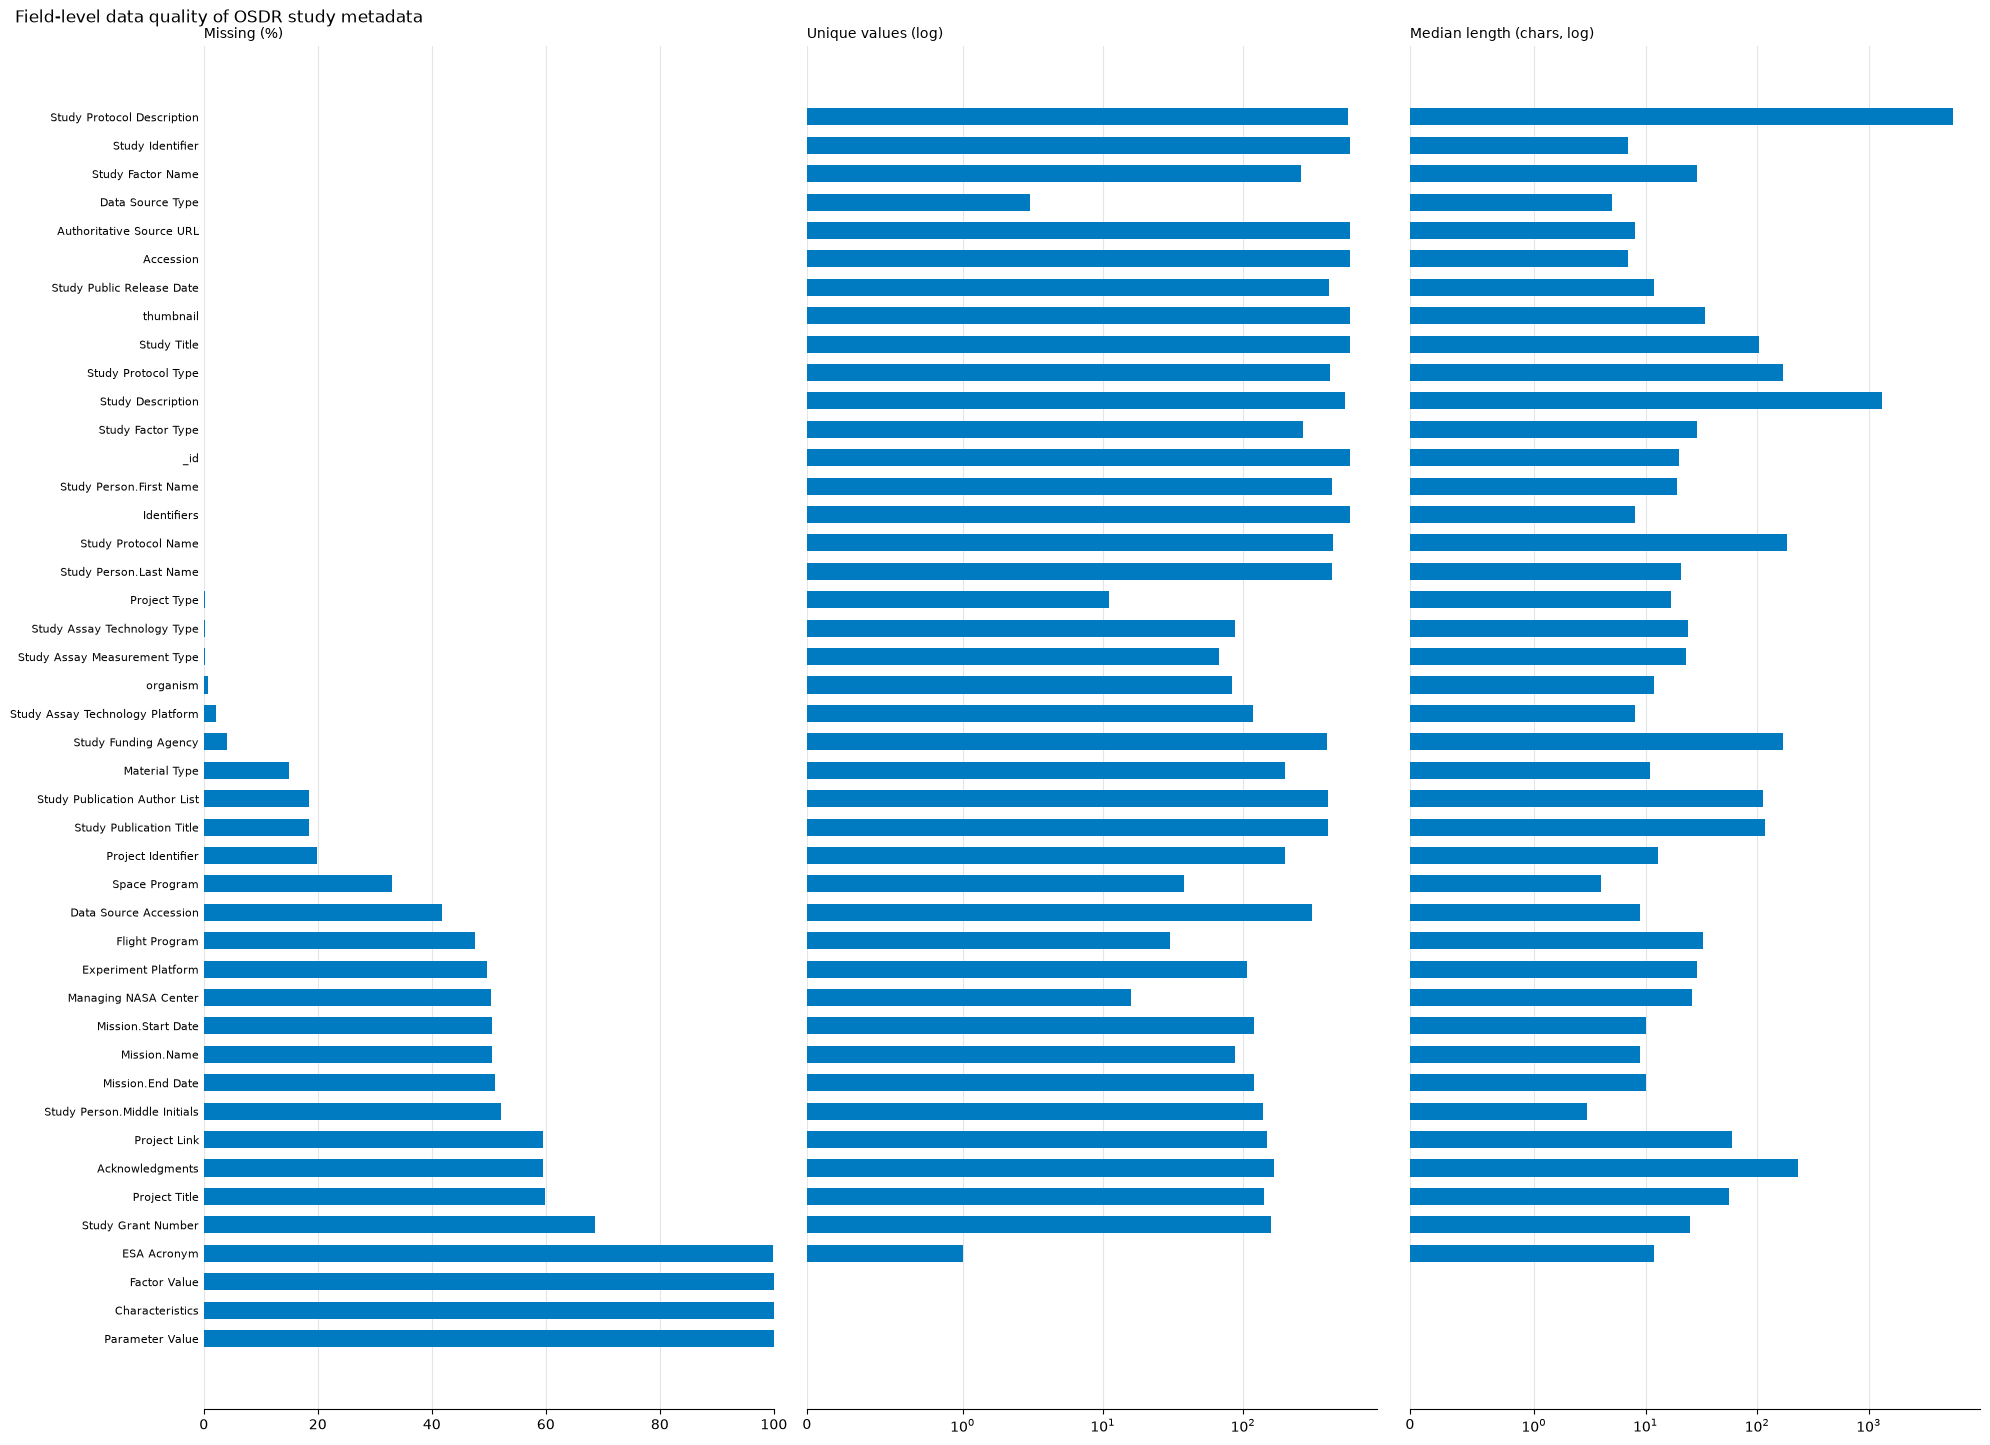

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def column_profile(df: pd.DataFrame) -> pd.DataFrame:
    """One row per column with simple data-quality metrics."""
    rows = []
    for col in df.columns:
        s = df[col].astype("string").str.strip()
        # empty strings and empty JSON lists/dicts also count as missing
        is_missing = s.isna() | s.isin(["", "[]", "{}", "nan", "None"])
        present = s[~is_missing]
        n = len(present)
        rows.append({
            "column": col,
            "missing_pct": 100 * is_missing.mean(),
            "n_unique": present.nunique(),
            # how many distinct values collapse after lowercasing + whitespace cleanup
            # "variant_pct": 100 * (1 - present.str.lower().str.replace(r"\s+", " ", regex=True).nunique()
                                #   / present.nunique()) if n else 0,
            "median_len": present.str.len().median() if n else 0,
            # "list_pct": 100 * present.str.startswith("[").mean() if n else 0,
            # "numeric_like_pct": 100 * pd.to_numeric(present, errors="coerce").notna().mean() if n else 0,
        })
    return pd.DataFrame(rows).set_index("column").sort_values("missing_pct")


def plot_profile(profile: pd.DataFrame, color="#007bc2"):
    panels = [
        ("missing_pct",      "Missing (%)",                     (0, 100), False),
        ("n_unique",         "Unique values (log)",             None,     True),
        # ("variant_pct",      "Case/space variants (%)",         (0, 100), False),
        ("median_len",       "Median length (chars, log)",      None,     True),
        # ("list_pct",         "Stored as list (%)",              (0, 100), False),
        # ("numeric_like_pct", "Numeric-looking (%)",             (0, 100), False),
    ]
    fig, axes = plt.subplots(1, len(panels), sharey=True,
                             figsize=(20, 0.3 * len(profile) + 1.5))
    y = np.arange(len(profile))
    for ax, (metric, title, xlim, log) in zip(axes, panels):
        ax.barh(y, profile[metric].fillna(0), height=0.6, color=color)
        ax.set_title(title, fontsize=10, loc="left")
        if xlim:
            ax.set_xlim(*xlim)
        if log:
            ax.set_xscale("symlog", linthresh=1)
        ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.tick_params(axis="y", length=0)
    axes[0].set_yticks(y, profile.index, fontsize=8)
    axes[0].invert_yaxis()          # most complete field at the top
    fig.suptitle("Field-level data quality of OSDR study metadata",
                 x=0.01, ha="left", fontsize=12)
    fig.tight_layout()
    return fig


profile = column_profile(df)
display(profile.round(1))           # table view for exact numbers
fig = plot_profile(profile)
plt.show()

In [32]:
t1 = [
    "Study Description",
    "Study Title",
    "Accession",
    "organism",
    "Material Type",
    "Study Assay Measurement Type",
    "Study Assay Technology Type",
    "Study Factor Name",
    # "Factor Value",
    "Mission.Name",
    "Flight Program",
    "Space Program",
    "Project Type",
    "Study Public Release Date",
]

t2 = [
    "Study Protocol Description",
    "Study Protocol Type",
    "Study Protocol Name",
    # "ESA Acronym",
    "Experiment Platform",
    # "Characteristics",
    "Study Assay Technology Platform",
    "Study Publication Title",
    "Mission.Start Date",
    "Mission.End Date",
    "Project Title",
    "Study Funding Agency",
    "Authoritative Source URL",
    "Project Link",
]

,missing_pct,n_unique,median_len
column,,,
Study Description,0.0,531,1320.0
Study Title,0.0,575,104.0
Accession,0.0,576,7.0
Study Factor Name,0.0,260,29.0
Study Public Release Date,0.0,409,12.0
Study Assay Technology Type,0.2,88,24.0
Project Type,0.2,11,17.0
Study Assay Measurement Type,0.2,67,23.0
organism,0.7,83,12.0


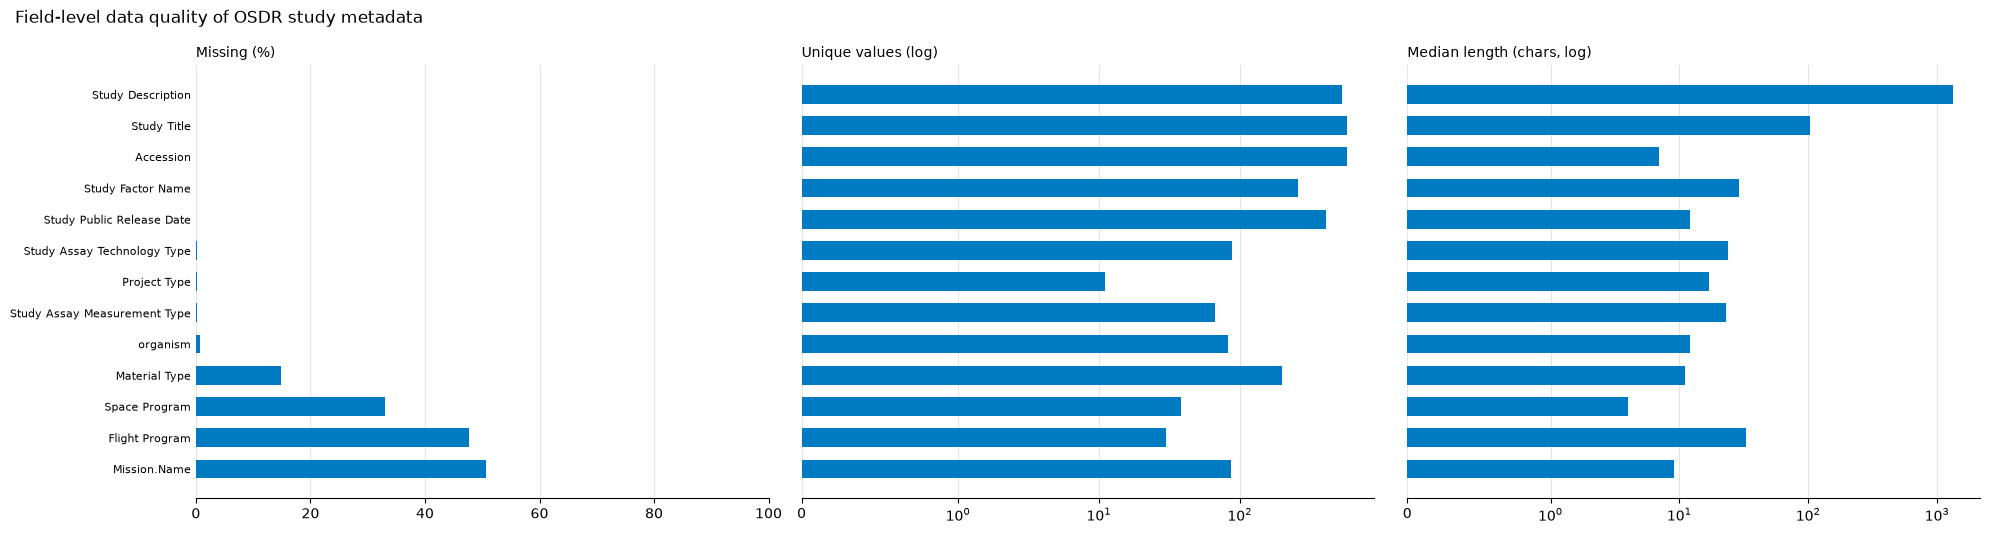

,missing_pct,n_unique,median_len
column,,,
Study Protocol Description,0.0,563,5671.0
Study Protocol Type,0.0,420,172.0
Study Protocol Name,0.0,440,185.0
Authoritative Source URL,0.0,576,8.0
Study Assay Technology Platform,2.1,117,8.0
Study Funding Agency,4.2,394,169.0
Study Publication Title,18.5,404,116.5
Experiment Platform,49.7,107,29.0
Mission.Start Date,50.6,120,10.0


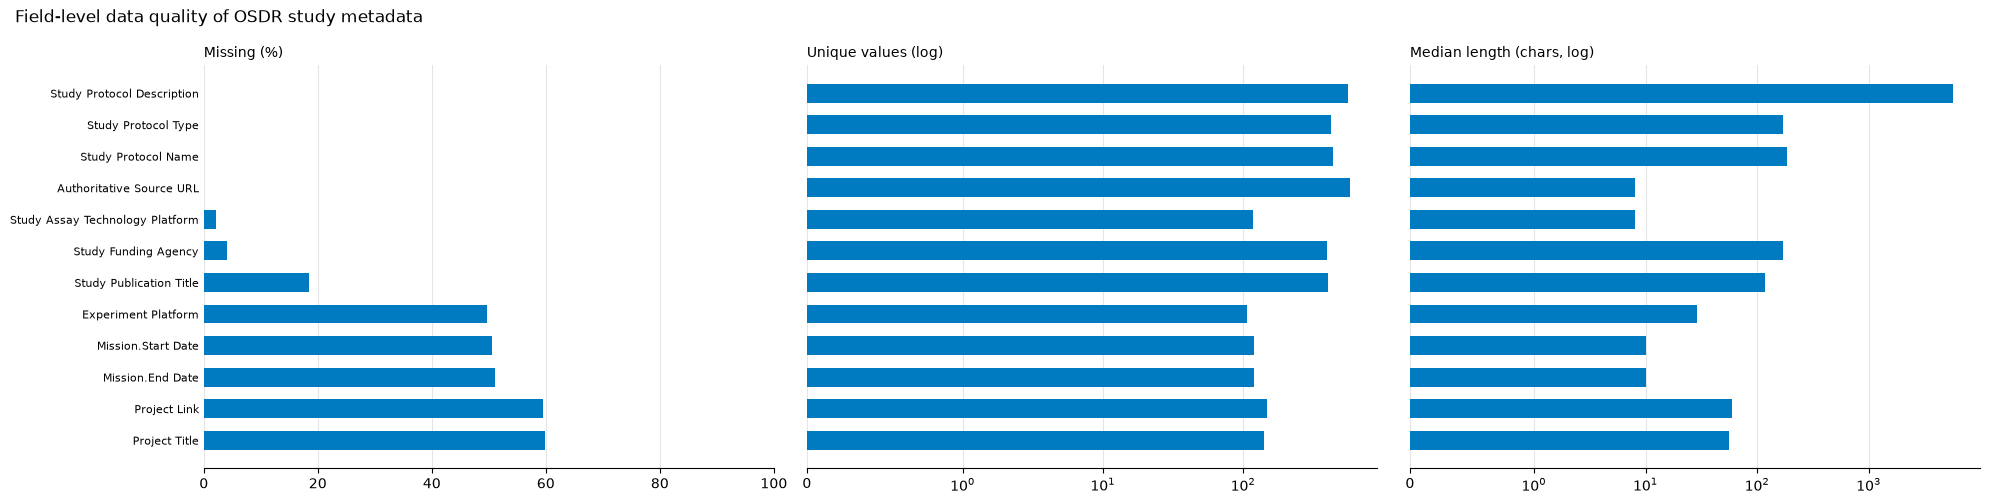

In [33]:
df_t1 = df[t1]

profile = column_profile(df_t1)
display(profile.round(1))           # table view for exact numbers
fig = plot_profile(profile)
plt.show()

df_t2 = df[t2]

profile = column_profile(df_t2)
display(profile.round(1))           # table view for exact numbers
fig = plot_profile(profile)
plt.show()